In [99]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [100]:
df=pd.read_csv("/content/Housing-selected-columns(7).csv")

In [101]:
print(x.columns)

Index(['area', 'bedrooms', 'bathrooms', 'stories'], dtype='object')


In [102]:
df

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning
0,13300000,7420,4,2,3,yes,no,no,no,yes
1,12250000,8960,4,4,4,yes,no,no,no,yes
2,12250000,9960,3,2,2,yes,no,yes,no,no
3,12215000,7500,4,2,2,yes,no,yes,no,yes
4,11410000,7420,4,1,2,yes,yes,yes,no,yes
...,...,...,...,...,...,...,...,...,...,...
540,1820000,3000,2,1,1,yes,no,yes,no,no
541,1767150,2400,3,1,1,no,no,no,no,no
542,1750000,3620,2,1,1,yes,no,no,no,no
543,1750000,2910,3,1,1,no,no,no,no,no


In [103]:
x = df.drop(['price', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning'], axis=1, errors='ignore')
y = df['price']

In [104]:
df.replace({'yes':1,'no':0},inplace=True)

/tmp/ipykernel_1539/334416500.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.replace({'yes':1,'no':0},inplace=True)


In [105]:
df

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning
0,13300000,7420,4,2,3,1,0,0,0,1
1,12250000,8960,4,4,4,1,0,0,0,1
2,12250000,9960,3,2,2,1,0,1,0,0
3,12215000,7500,4,2,2,1,0,1,0,1
4,11410000,7420,4,1,2,1,1,1,0,1
...,...,...,...,...,...,...,...,...,...,...
540,1820000,3000,2,1,1,1,0,1,0,0
541,1767150,2400,3,1,1,0,0,0,0,0
542,1750000,3620,2,1,1,1,0,0,0,0
543,1750000,2910,3,1,1,0,0,0,0,0


In [106]:
df.isna().sum()

,0
price,0
area,0
bedrooms,0
bathrooms,0
stories,0
mainroad,0
guestroom,0
basement,0
hotwaterheating,0
airconditioning,0


In [107]:
df.info

<bound method DataFrame.info of         price  area  bedrooms  bathrooms  stories  mainroad  guestroom  \
0    13300000  7420         4          2        3         1          0   
1    12250000  8960         4          4        4         1          0   
2    12250000  9960         3          2        2         1          0   
3    12215000  7500         4          2        2         1          0   
4    11410000  7420         4          1        2         1          1   
..        ...   ...       ...        ...      ...       ...        ...   
540   1820000  3000         2          1        1         1          0   
541   1767150  2400         3          1        1         0          0   
542   1750000  3620         2          1        1         1          0   
543   1750000  2910         3          1        1         0          0   
544   1750000  3850         3          1        2         1          0   

     basement  hotwaterheating  airconditioning  
0           0                0                1  
1           0                0                1  
2           1                0                0  
3           1                0                1  
4           1                0                1  
..        ...              ...              ...  
540         1                0                0  
541         0                0                0  
542         0                0                0  
543         0                0                0  
544         0                0                0  

[545 rows x 10 columns]>

In [108]:
df.describe()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.858716,0.177982,0.350459,0.045872,0.315596
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.348635,0.382849,0.477552,0.209399,0.465180
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000,0.000000,1.000000,0.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,1.000000,1.000000,1.000000,1.000000,1.000000


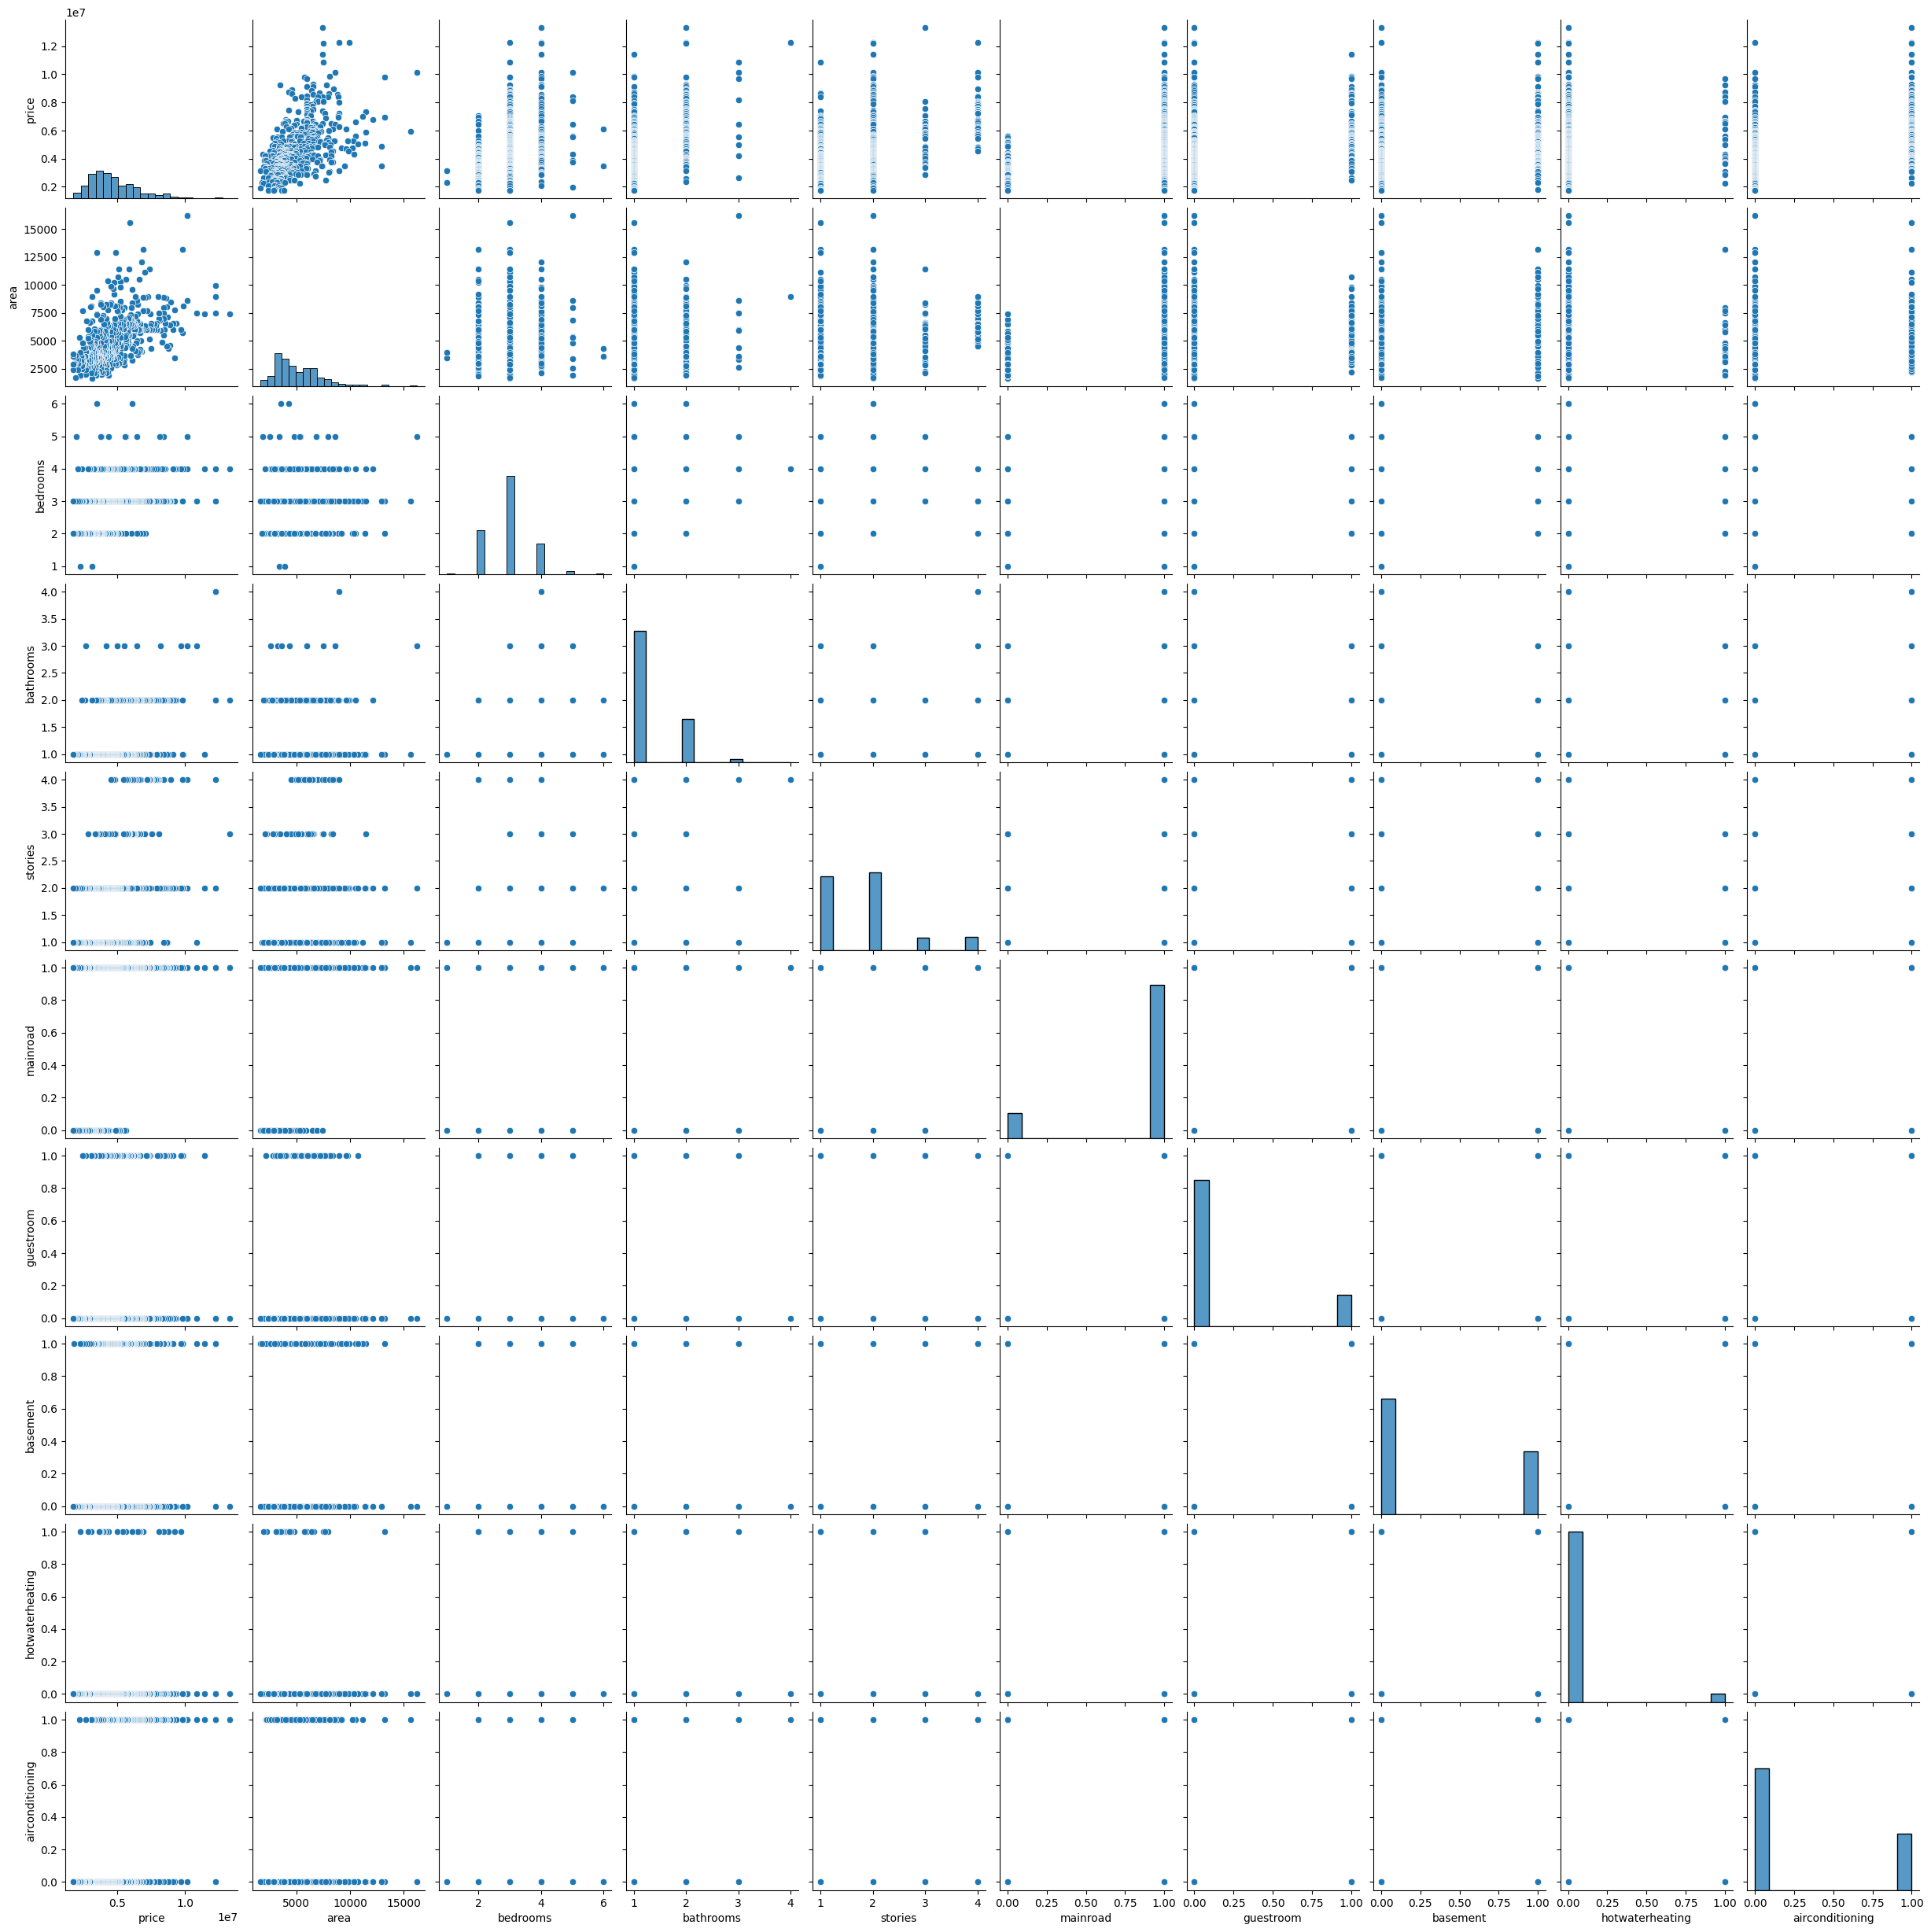

In [109]:
sns.pairplot(df)

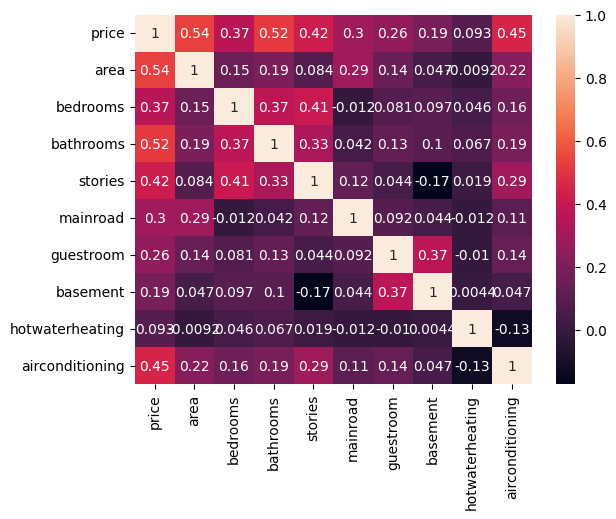

In [110]:
sns.heatmap(df.corr(numeric_only=True), annot=True)
plt.show()

In [111]:
from sklearn.model_selection import train_test_split

In [112]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2, random_state=42)

In [113]:
from sklearn.linear_model import LinearRegression
model=LinearRegression()
model.fit(x_train,y_train)

LinearRegression()

In [114]:
from sklearn.metrics import r2_score
y_pred=model.predict(x_test)
score=r2_score(y_test,y_pred)
print("r2 score:", score)

r2 score: 0.513758534903707
